# Gaussian peak statistics analyisi and comparison with BBKS results

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, simpson
from scipy.special import spherical_jn, hyp1f1, erf
from scipy.optimize import minimize

plt.rcParams.update({"figure.figsize": (7.5, 5), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 1.8})


## 1. Input: the power spectrum

Input the dimensionless powe spectrum of choiche, generic function of $k$. The code was built upon the dimensionful power spectrum as a leftover from BBKS calculations but the dimensionless one is more meaningful so we insert this


In [3]:
def dimensionless_power_spectrum(k):
    A, n, R_f = 1e-2, 3, 1.0
    return A * np.asarray(k)**n * np.exp(-(np.asarray(k) * R_f)**2)

def power_spectrum(k):
    return dimensionless_power_spectrum(k) * (2*np.pi**2) / k**3

# integration range for all the spectral integrals below - adjust if your
# power_spectrum decays much more slowly/quickly than the default example
K_MIN, K_MAX = 1e-10, 20.0

# Only used for the optional analytic cross-checks in Sections 2-3, which are valid
# exclusively for the power-law-times-Gaussian form above. Keep n_pl, Rf_pl in sync
# with the constants inside power_spectrum, or set IS_POWERLAW_GAUSSIAN = False.
# The polynomial exponent to add here is the one of the DIMENSIONFUL power spectrum
IS_POWERLAW_GAUSSIAN = True
n_pl, Rf_pl = 0, 1.0

## 2. Spectral moments and the derived parameters $\gamma$, $R_*$

$$
\sigma_j^2=\int_0^\infty d\ln k\,k^{2j}\mathcal{P}(k),
\qquad
\gamma=\frac{\sigma_1^2}{\sigma_0\sigma_2},
\qquad
R_*=\sqrt3\,\frac{\sigma_1}{\sigma_2}.
$$


In [4]:
def spectral_moment(j, kmin=K_MIN, kmax=K_MAX):
    '''sigma_j^2 = 1/(2 pi^2) * integral_0^inf dk k^(2+2j) P(k)W^2(k)  (adaptive quadrature).'''
    integrand = lambda k: k**(2 + 2 * j) * power_spectrum(k) / (2.0 * np.pi**2)
    val, _ = quad(integrand, kmin, kmax, limit=400)
    return val


sigma0 = np.sqrt(spectral_moment(0))
sigma1 = np.sqrt(spectral_moment(1))
sigma2 = np.sqrt(spectral_moment(2))
gamma  = sigma1**2 / (sigma0 * sigma2)
Rstar  = np.sqrt(3.0) * sigma1 / sigma2

print(f"  sigma_0 = {sigma0:.6e}")
print(f"  sigma_1 = {sigma1:.6e}")
print(f"  sigma_2 = {sigma2:.6e}")
print(f"  gamma   = {gamma:.6f}        [= sigma_1^2/(sigma_0 sigma_2)]")
print(f"  R_*     = {Rstar:.6f}        [= sqrt(3) sigma_1/sigma_2]")

if IS_POWERLAW_GAUSSIAN:
    # analytic cross-check, valid only for P(k)W^2 = A k^n exp(-(k R_f)^2)  (BBKS eq. E3)
    g_exact = np.sqrt((n_pl + 3) / (n_pl + 5))
    Rs_exact = Rf_pl * np.sqrt(6.0 / (n_pl + 5))
    print(f"\nanalytic check (power law + Gaussian):  gamma = {g_exact:.6f},  R_* = {Rs_exact:.6f}")


  sigma_0 = 6.656677e-02
  sigma_1 = 8.152731e-02
  sigma_2 = 1.289060e-01
  gamma   = 0.774597        [= sigma_1^2/(sigma_0 sigma_2)]
  R_*     = 1.095445        [= sqrt(3) sigma_1/sigma_2]

analytic check (power law + Gaussian):  gamma = 0.774597,  R_* = 1.095445


## 3. The correlation-function building blocks $\psi,\psi',\nabla^2\psi,S$

With $u\equiv r/R_*$, the quantities entering the BBKS profile formulas (7.8)-(7.10) are,
directly as spectral integrals over `power_spectrum`,

$$
\mathcal{P}(k) \equiv \frac{k^3 P(k) W^2(k)}{2\pi^2}, \qquad
\sigma_0^2 = \int \frac{dk}{k}\,\mathcal{P}(k)
$$

$$
\psi(u)=\frac{1}{\sigma_0^2}\int \frac{dk}{k}\,\mathcal{P}(k)\, j_0(kR_*u)
$$

$$
\frac{d\psi}{du}=-\frac{R_*}{\sigma_0^2}\int dk\,\mathcal{P}(k)\, j_1(kR_*u)
$$

$$
\nabla^2\psi=-\frac{R_*^2}{\sigma_0^2}\int dk\,k\,\mathcal{P}(k)\, j_0(kR_*u)
$$

$$
S(u)\equiv\frac{\psi'}{u}-\frac{\nabla^2\psi}{3}
=-\frac{R_*^2}{3\sigma_0^2}\int dk\,k\,\mathcal{P}(k)\, j_2(kR_*u)
$$

`profile_functions(u)` below evaluates all four at once, for any array of $u$, using a
fixed Gauss-Legendre rule set up once from `power_spectrum`, `sigma0`, `Rstar` (fast and
vectorised — this replaces the adaptive quadrature of `spectral_moment`, which is only
accurate/fast enough for the handful of one-off integrals of Section 2).


In [5]:
def _setup_gauss_legendre(kmin=K_MIN, kmax=K_MAX, nk=5000):
    xg, wg = np.polynomial.legendre.leggauss(nk)
    k_nodes = 0.5 * (kmax - kmin) * xg + 0.5 * (kmax + kmin)
    w_nodes = 0.5 * (kmax - kmin) * wg
    base = w_nodes * power_spectrum(k_nodes) / (2.0 * np.pi**2 * sigma0**2)
    return k_nodes, w_nodes, base


_k_nodes, _w_nodes, _base = _setup_gauss_legendre()


def profile_functions(u):
    '''psi, dpsi/du, lap psi, S = psi'/u - lap psi/3   at u = r/Rstar.'''
    u = np.atleast_1d(np.asarray(u, float))
    Y = np.outer(u, _k_nodes * Rstar)                 # (n_u, n_k)
    j0, j1, j2 = (spherical_jn(m, Y) for m in (0, 1, 2))
    k, b = _k_nodes, _base
    psi = j0 @ (b * k**2)
    dpsi = -Rstar * (j1 @ (b * k**3))
    lap = -Rstar**2 * (j0 @ (b * k**4))
    S = -(Rstar**2 / 3.0) * (j2 @ (b * k**4))
    return psi, dpsi, lap, S


## 5. Peak statistics: the curvature $x$ given the height $\nu$

Functions needed for the evaluation of marginalized profile distribution


In [6]:
def f_bbks(x):
    '''BBKS eq. (A15). The small-x series (A16) is used below x = 0.2, where the
    closed form suffers from catastrophic cancellation.'''
    x = np.atleast_1d(np.asarray(x, float))
    out = np.empty_like(x)
    sm = x < 0.2
    xs, xb = x[sm], x[~sm]
    out[sm] = (3**5 * 5**1.5 / (7 * 2**11 * np.sqrt(2 * np.pi))) * xs**8 * (1 - 5 * xs**2 / 8)
    out[~sm] = ((xb**3 - 3 * xb) * (erf(np.sqrt(2.5) * xb) + erf(np.sqrt(2.5) * xb / 2)) / 2
                + np.sqrt(2 / (5 * np.pi)) * ((31 * xb**2 / 4 + 8 / 5) * np.exp(-5 * xb**2 / 8)
                                              + (xb**2 / 2 - 8 / 5) * np.exp(-5 * xb**2 / 2)))
    return out


def P_x_given_nu(x, gamma, nu):
    '''BBKS eq. (7.5), up to the normalisation G(gamma, x_*).'''
    xstar = gamma * nu
    return (f_bbks(x) * np.exp(-(x - xstar)**2 / (2 * (1 - gamma**2)))
            / np.sqrt(2 * np.pi * (1 - gamma**2)))


def x_stats(gamma, nu):
    '''x_* = gamma nu, the conditional mean <x|nu> (eq. 6.13), the most probable x
    (mode), and the conditional standard deviation.'''
    if not np.isfinite(gamma) or not (0 < gamma < 1):
        raise ValueError(f"x_stats needs 0 < gamma < 1, got gamma = {gamma}. A NaN or a value "
                         f"above 1 means the spectral moments are wrong.")
    w = lambda t: float(np.asarray(P_x_given_nu(t, gamma, nu)).reshape(-1)[0])
    norm = quad(w, 0, np.inf, limit=400)[0]
    mean = quad(lambda t: t * w(t), 0, np.inf, limit=400)[0] / norm
    variance = np.sqrt(quad(lambda t: (t - mean)**2 * w(t), 0, np.inf, limit=400)[0] / norm)
    grid = np.linspace(1e-3, 15.0, 30001)
    mode = float(grid[np.argmax(P_x_given_nu(grid, gamma, nu))])
    return gamma * nu, mean, mode, variance


def average_curvature(nu, gamma=gamma):
    '''Convenience wrapper: the average (conditional-mean) curvature <x|nu>
    for a peak of height nu, given the spectral parameter gamma computed in Section 2.'''
    return x_stats(gamma, nu)[1]

## 6. Mean shape functions


In [7]:
def A_angular(e, p, theta, phi):
    '''BBKS eq. (7.4); 1-axis is the polar axis, x3 = r sin(theta) sin(phi).'''
    st2 = np.sin(theta)**2
    return 3 * e * (1 - st2 * (1 + np.sin(phi)**2)) + p * (1 - 3 * st2 * np.cos(phi)**2)


def A_principal(e, p):
    '''A(e,p) along the 1-, 2- and 3-axis.'''
    return 3 * e + p, -2 * p, p - 3 * e


def ep_allowed(e, p):
    '''characteristic function chi(e,p), BBKS eq. (C3).'''
    if 0 <= e <= 0.25:
        return -e <= p <= e
    if 0.25 < e <= 0.5:
        return -(1 - 3 * e) <= p <= e
    return False


def mean_profile(u, nu, x, A, gamma=gamma, funcs=None):
    '''BBKS eq. (7.8)  ->  Fbar(r)/sigma_0.  A = A(e,p) for the chosen direction
    (A = 0 gives the orientation-averaged eq. 7.10).'''
    psi, dpsi, lap, S = profile_functions(u) if funcs is None else funcs
    g = gamma
    return (nu / (1 - g**2) * (psi + lap / 3)
            - (x / g) / (1 - g**2) * (g**2 * psi + lap / 3)
            + 2.5 * (x / g) * S * A)


def profile_dispersion(u, gamma=gamma, funcs=None):
    '''BBKS eq. (7.9)  ->  sqrt(<dF^2|C>)/sigma_0.  Independent of nu, x, e, p.'''
    psi, dpsi, lap, S = profile_functions(u) if funcs is None else funcs
    g = gamma
    var = (1 - psi**2 / (1 - g**2)
           - (1 / (g**2 * (1 - g**2))) * (2 * g**2 * psi + lap / 3) * (lap / 3)
           - (5 / g**2) * S**2
           - (1 / g**2) * dpsi**2)
    return np.sqrt(np.clip(var, 0, None))


In [8]:
def P_ep_given_x(x, e_grid, p_grid):
    """
    Normalized BBKS joint probability density P(e,p|x).

    Parameters
    ----------
    x : float or array_like
        Peak curvature(s).
    e_grid, p_grid : 1D arrays
        Grids for ellipticity and prolateness.

    Returns
    -------
    pdf : ndarray
        Shape (n_x, n_e, n_p).
        Normalized independently for each x.
    """
    x = np.atleast_1d(x)

    E, P = np.meshgrid(e_grid, p_grid, indexing='ij')

    # BBKS domain, eq. (C3)
    lower = np.where(E <= 0.25, -E, -(1 - 3 * E))
    domain = (P >= lower) & (P <= E)

    # BBKS shape distribution, eq. (C4)
    Wpoly = (
        E * (E**2 - P**2)
        * (1 - 2 * P)
        * ((1 + P)**2 - 9 * E**2)
    )
    Wpoly = np.where(domain & (Wpoly > 0), Wpoly, 0.0)

    Q = 3 * E**2 + P**2

    pdf = (
        Wpoly[None, :, :]
        * np.exp(-2.5 * x[:, None, None]**2 * Q[None, :, :])
    )

    # Normalize over e and p for every x
    norm = simpson(
        simpson(pdf, x=p_grid, axis=2),
        x=e_grid,
        axis=1
    )

    pdf /= norm[:, None, None]

    return pdf

def average_ep_given_nu(nu, gamma=gamma,n_e=121, n_p=121, n_x=121, x_max=None):
    """
    Compute <e|nu> and <p|nu> by averaging the normalized
    BBKS shape distribution over the curvature distribution
    P(x|nu).
    """
    if x_max is None:
        x_max = gamma * nu + 6.0 / np.sqrt(1 - gamma**2)

    # Integration grids
    e_grid = np.linspace(1e-4, 0.5, n_e)
    p_grid = np.linspace(-0.5, 0.5, n_p)
    x_grid = np.linspace(1e-4, x_max, n_x)

    E, P = np.meshgrid(e_grid, p_grid, indexing='ij')

    # Normalized P(e,p|x)
    pdf = P_ep_given_x(x_grid, e_grid, p_grid)

    # Conditional means at fixed curvature x
    mean_e_given_x = simpson(
        simpson(pdf * E[None, :, :], x=p_grid, axis=2),
        x=e_grid,
        axis=1
    )

    mean_p_given_x = simpson(
        simpson(pdf * P[None, :, :], x=p_grid, axis=2),
        x=e_grid,
        axis=1
    )

    # Average over P(x|nu)
    w_x = P_x_given_nu(x_grid, gamma, nu)
    norm = simpson(w_x, x=x_grid)

    e_avg = simpson(
        w_x * mean_e_given_x, x=x_grid
    ) / norm

    p_avg = simpson(
        w_x * mean_p_given_x, x=x_grid
    ) / norm

    return e_avg, p_avg

# example
nu_demo2 = 3.0
e_avg, p_avg = average_ep_given_nu(nu_demo2)

## 8. Comparing simulated profiles from a `.csv` against the theoretical average

The cell below expects a `.csv` in the same format produced by the ```Peaks_generator_general.py``` script.

`load_profiles_csv` reads the file; `compare_profiles_to_theory` selects the peaks whose
height falls in $[\nu-\delta\nu/2,\ \nu+\delta\nu/2]$, overlays them on the theoretical
spherical mean $\pm1\sigma$ band, plots their empirical average.


In [9]:
def sample_x_e_p_given_nu(nu, gamma=gamma, n_samples=20000,
                           n_x=161, n_e=161, n_p=161, x_max=None, rng=None):
    '''Draw samples (x, e, p) from the joint conditional distribution P(x,e,p|nu), BBKS.

    The FULL unconditional (curvature, shape) density is (BBKS eq. C4, with the correct
    x^8 prefactor -- this is the piece that was missing/wrong before):

        N(x,e,p) propto x^8 * Wpoly(e,p) * exp(-5x^2 Q(e,p)/2),
        Wpoly(e,p) = e(e^2-p^2)(1-2p)[(1+p)^2-9e^2],   Q(e,p) = 3e^2+p^2,

    on the domain 0<=e<=1/2 (eq. C3). Conditioning on nu multiplies this by the
    (x-nu) correlation Gaussian, exp[-(x-x*)^2/(2(1-gamma^2))] with x*=gamma*nu:

        P(x,e,p|nu) propto exp[-(x-x*)^2/(2(1-gamma^2))] * x^8 * Wpoly * exp(-5x^2Q/2).

    Marginalising this over (e,p) reproduces f_bbks(x) up to a constant, and marginalising
    over x reproduces average_ep_given_nu -- both checked numerically to confirm this is
    the correct joint (earlier versions either double-counted f(x) or dropped x^8 entirely).
    '''
    rng = np.random.default_rng() if rng is None else rng
    if x_max is None:
        x_max = gamma * nu + 6.0 / np.sqrt(1 - gamma**2)

    x_grid = np.linspace(1e-4, x_max, n_x)
    e_grid = np.linspace(1e-4, 0.5, n_e)
    p_grid = np.linspace(-0.5, 0.5, n_p)
    X, E, P = np.meshgrid(x_grid, e_grid, p_grid, indexing='ij')

    lower = np.where(E <= 0.25, -E, -(1 - 3 * E))
    domain = (P >= lower) & (P <= E)
    Wpoly = E * (E**2 - P**2) * (1 - 2 * P) * ((1 + P)**2 - 9 * E**2)
    Wpoly = np.where(domain & (Wpoly > 0), Wpoly, 0.0)

    x_star = gamma * nu
    joint = (np.exp(-(X - x_star)**2 / (2 * (1 - gamma**2)))
             * X**8 * Wpoly * np.exp(-2.5 * X**2 * (3 * E**2 + P**2)))

    probs = joint.ravel()
    probs = probs / probs.sum()

    idx = rng.choice(probs.size, size=n_samples, p=probs)
    ix, ie, ip = np.unravel_index(idx, joint.shape)

    dx, de, dp = x_grid[1] - x_grid[0], e_grid[1] - e_grid[0], p_grid[1] - p_grid[0]
    x_s = np.clip(x_grid[ix] + rng.uniform(-dx / 2, dx / 2, n_samples), 1e-6, None)
    e_s = np.clip(e_grid[ie] + rng.uniform(-de / 2, de / 2, n_samples), 1e-6, 0.5)
    p_s = np.clip(p_grid[ip] + rng.uniform(-dp / 2, dp / 2, n_samples), -0.5, 0.5)
    return x_s, e_s, p_s


def profile_distribution_at_r_full(u, nu, gamma=gamma, n_samples=20000,
                                    n_x=81, n_e=81, n_p=81,
                                    F_grid=None, n_F=400, rng=None, sigma=None):
    '''
    The accurate spherically-averaged distribution of the profile value F at r/R_star = u,
    for peaks of height nu: convolves the fixed-sigma Gaussian (BBKS eq. 7.9) with the
    FULL JOINT distribution of curvature x and shape (e, p) given nu, and with the uniform
    distribution of orientation (theta, phi) -- rather than fixing x, e, p at their means.

    Returns
    -------
    F_grid   : ndarray            grid of profile values where P(F|u,nu) is evaluated
    P_F      : ndarray            normalised density P(F|u,nu) on F_grid
    F_mean   : float              mean of the computed distribution, int F P(F|u,nu) dF
    sigma    : float              the (direction-independent) BBKS dispersion at this u
    means    : ndarray            the per-sample means (x_i, e_i, p_i, theta_i, phi_i) used
    '''

    rng = np.random.default_rng() if rng is None else rng
    funcs = profile_functions(u)
    if sigma is None:
        sigma = profile_dispersion(u, gamma, funcs).item()
    x_s, e_s, p_s = sample_x_e_p_given_nu(nu, gamma, n_samples, n_x, n_e, n_p, rng=rng)

    cos_theta = rng.uniform(-1.0, 1.0, n_samples)         # uniform on the sphere
    theta_s = np.arccos(cos_theta)
    phi_s = rng.uniform(0.0, 2 * np.pi, n_samples)

    A_s = A_angular(e_s, p_s, theta_s, phi_s)
    means = mean_profile(u, nu, x_s, A_s, gamma, funcs)     # (n_samples,)

    if sigma > 0:
        if F_grid is None:
            F_lo = means.min() - 5 * sigma
            F_hi = means.max() + 5 * sigma
            F_grid = np.linspace(F_lo, F_hi, n_F)

        diff = (F_grid[:, None] - means[None, :]) / sigma
        P_F = (np.exp(-0.5 * diff**2) / (sigma * np.sqrt(2 * np.pi))).mean(axis=1)
        P_F /= simpson(P_F, x=F_grid)

        F_mean = simpson(F_grid * P_F, x=F_grid)
        F_var = simpson((F_grid - F_mean)**2 * P_F, x=F_grid)
        F_std = np.sqrt(F_var)
        return F_grid, P_F, F_mean, F_std, sigma, means
    else:
        # sigma=0 case: the distribution is a delta function at the mean
        F_mean = means.mean()
        return np.array([F_mean]), np.array([1.0]), F_mean, 0.0, sigma, means

In [10]:
import csv
import scipy.stats as stats


def read_u_common(path):
    """Read the shared u grid from the first nonempty row."""
    with open(path, newline="") as f:
        reader = csv.reader(f)
        for row in reader:
            if row:
                return np.array(row, dtype=float)
    raise ValueError("CSV file is empty.")


def iter_profiles_csv(path):
    """Yield one profile y at a time (u is stored in the first row)."""
    with open(path, newline="") as f:
        reader = csv.reader(f)

        # Skip the first nonempty row (the u grid)
        for row in reader:
            if row:
                break

        # Stream the remaining rows one by one
        for row in reader:
            if row:
                yield np.array(row, dtype=float)



In [125]:
csv_path = "peaks_gauss_high.csv"
nu = 4
dnu = 0.01

r_hist = 3
band_nsigma = 1.0

# Common grid, read once
u_common = read_u_common(csv_path)
du = u_common[1] - u_common[0]
i_hist = int(round(r_hist / du))
print(f"Actual radius of the sampled distribution = {u_common[i_hist]}, du = {du}")

n_sel = 0
profile_sum = None
heights_at_r_hist = []
selected_profiles = []

# 1. Extract selected profiles
for y in iter_profiles_csv(csv_path):

    # Reject peaks outside the requested height window
    if not (nu - dnu / 2 <= y[0] <= nu + dnu / 2):
        continue

    # Store selected profiles for plotting later
    selected_profiles.append(y)

    # Update running sum
    if profile_sum is None:
        profile_sum = y.copy()
    else:
        min_len = min(len(profile_sum), len(y))
        profile_sum = profile_sum[:min_len]
        profile_sum += y[:min_len]

    n_sel += 1

    if i_hist < len(y):
        heights_at_r_hist.append(y[i_hist])

Actual radius of the sampled distribution = 2.9953577363563775, du = 0.142636082683637


In [126]:
u_profile = u_common
funcs_plot = profile_functions(u_common)          # computed once, reused everywhere below
sig_plot = profile_dispersion(u_common, gamma, funcs_plot)

x_mean = average_curvature(nu)
m0 = mean_profile(u_common, nu, x_mean, 0.0, gamma, funcs_plot)
sig = sig_plot  

In [127]:
# Calculate theoretical prediction

p_avg = np.zeros_like(u_common)
p_std = np.zeros_like(u_common)
for u in u_common:
    F_grid, P_F, F_mean, F_std, sigma, means = profile_distribution_at_r_full(u, nu, gamma, n_samples=20000, n_x=64, n_e=64, n_p=64)
    p_avg[np.isclose(u_common, u)] = F_mean
    p_std[np.isclose(u_common, u)] = F_std

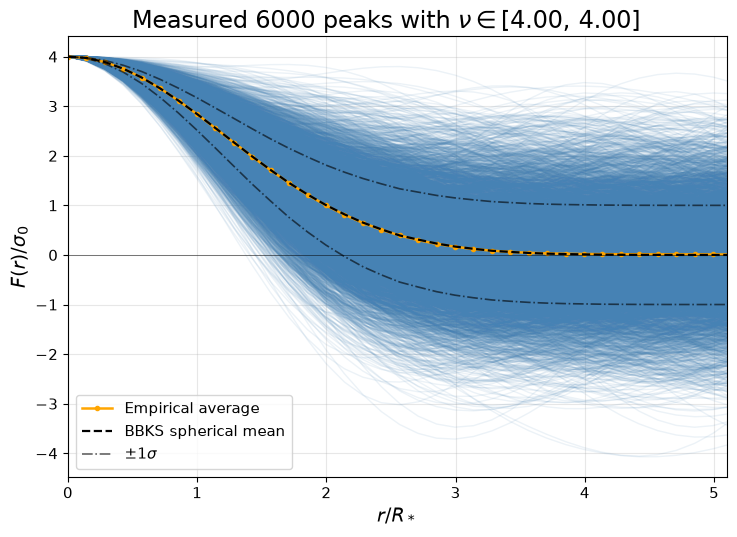

(-3.5, 6.0)

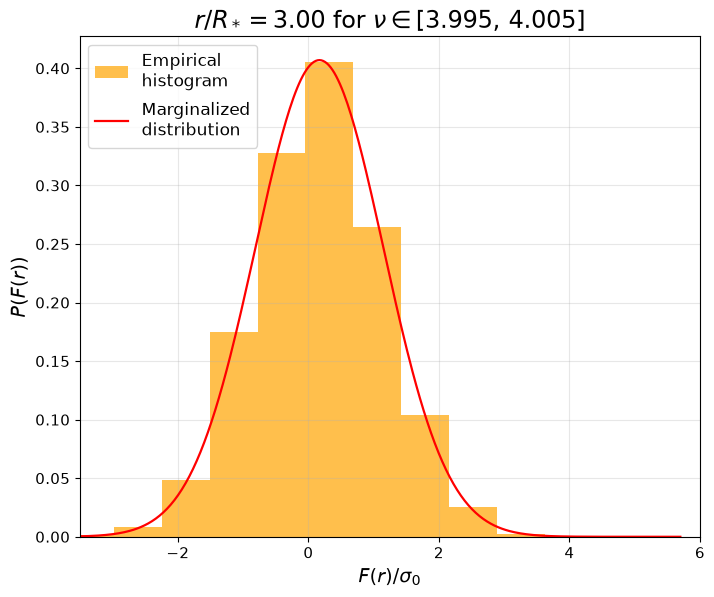

In [128]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
# 2. Plot selected profiles
for y in selected_profiles:
    ax.plot(u_common, y, color="steelblue", alpha=0.1, lw=1)


# 3. Calculate and plot empirical average
if n_sel == 0:
    print(
        f"No profiles found with height in "
        f"[{nu - dnu/2:.1f}, {nu + dnu/2:.1f}]."
    )
    empirical_mean = None
else:
    empirical_mean = profile_sum / n_sel

    ax.plot(u_common[:len(empirical_mean)],empirical_mean,color="orange",marker="o",markersize=3,label=f"Empirical average")

# Plot theoretical prediction
ax.plot(u_common, p_avg, "k--", lw=1.6,label=r"BBKS spherical mean")

#ax.fill_between(u_plot,m0 - band_nsigma * sig,m0 + band_nsigma * sig,color="red",alpha=0.25,label=fr"$\pm{band_nsigma:g}\sigma$")
#ax.fill_between(u_common,p_avg - band_nsigma * p_std,p_avg + band_nsigma * p_std,color="red",alpha=0.35,label=fr"$\pm{band_nsigma:g}\sigma$")
ax.plot(u_common, p_avg - band_nsigma * p_std, linestyle = "-.", color = "black", alpha = 0.6, lw=1.2)
ax.plot(u_common, p_avg + band_nsigma * p_std, linestyle = "-.", color = "black", alpha = 0.6, lw=1.2, label=fr"$\pm{band_nsigma:g}\sigma$")

ax.axhline(0, color="k", lw=0.7, alpha=0.5)

ax.set_xlabel(r"$r/R_*$", fontsize=14)
ax.set_ylabel(r"$F(r)/\sigma_0$", fontsize=14)

#ax.set_xlim(0.42,0.44)
#ax.set_ylim(-0.1,0.1)

ax.set_title(
    rf"Measured {n_sel} peaks with $\nu\in[{nu-dnu/2:.2f},\,{nu+dnu/2:.2f}]$   ", fontsize=17
)

u_ex = [u_common[i_hist]]

F_grid, P_F, F_mean, F_std, sigma, means = profile_distribution_at_r_full(u_ex, nu, gamma, n_samples=100000, n_x=128, n_e=128, n_p=128)

#plt.vlines(x=r_hist, ymin=F_mean - 4*F_std, ymax=F_mean + 4*F_std, color="k", lw=0.8, ls="--", alpha=0.5)
ax.set_xlim(0.0,5.1)
ax.legend(loc="lower left")
plt.tight_layout()

plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))

mu = m0[i_hist]
sigma = sig_plot[i_hist]
xga = np.linspace(np.min(heights_at_r_hist), np.max(heights_at_r_hist), 100)
_, bins, _ = plt.hist(heights_at_r_hist, density=True, bins=10, alpha=0.7, color="orange", label="Empirical\nhistogram")
dbin = bins[1] - bins[0]
ax.plot(F_grid, P_F, label="Marginalized\ndistribution", color="red", lw=1.6)
ax.set_title(rf"$r/R_*={u_common[i_hist]:.2f}$ for $\nu\in[{nu-dnu/2:.3f},\,{nu+dnu/2:.3f}]$", fontsize=17)
ax.set_xlabel(r"$F(r)/\sigma_0$", fontsize=14)
ax.set_ylabel(r"$P(F(r))$", fontsize=14)
ax.legend(loc="upper left", fontsize=12)
ax.set_xlim(-3.5,6)